# 01 — Comprensión de los datos (EDA)

**Fase CRISP-DM:** comprensión de los datos.

Dataset: *Fruit Quality Classification*, publicado en Kaggle por Ryan Park (licencia CC0), que redistribuye **FruitNet** [V. Meshram y K. Patil, *Data in Brief*, vol. 40, 107686, 2022]. Se descarga con `python -m src.data.descargar_datos`.

Preguntas:
1. ¿Qué frutas y qué clases de calidad hay, y cuántas imágenes por combinación?
2. ¿Hay desbalance?
3. ¿Cómo son las imágenes (resolución, fondo, iluminación, nitidez)?
4. ¿El color y las manchas oscuras separan las clases de calidad?
5. ¿Cómo son las imágenes `mixed_quality` y cuántas frutas tienen?

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from src.config import DATA_RAW_KAGGLE, DATA_PROCESSED, RESULTADOS, SEMILLA
from src.data.inventario import construir_inventario
from src.data.segmentacion import mascara_fruta, separar_frutas
from src.utils.visualizacion import estilo, guardar_figura, leer_rgb

estilo()
rng = np.random.default_rng(SEMILLA)
RESULTADOS.mkdir(parents=True, exist_ok=True)

## 1. Inventario

In [2]:
ruta_inv = DATA_PROCESSED / "inventario_kaggle.csv"
if ruta_inv.exists():
    inv = pd.read_csv(ruta_inv)
else:
    inv = construir_inventario(DATA_RAW_KAGGLE)
    inv.to_csv(ruta_inv, index=False)

print(f"Imágenes: {len(inv)}  |  legibles: {inv['legible'].sum()}")
print("Carpetas de primer nivel:", sorted({r.split('/')[0] for r in inv['ruta']}))
inv.head()

Imágenes: 19526  |  legibles: 19526
Carpetas de primer nivel: ['Bad Quality_Fruits', 'Good Quality_Fruits', 'Mixed Qualit_Fruits']


,ruta,fruta,calidad,bytes,legible,ancho,alto,brillo,saturacion,contraste,nitidez,fondo_v,md5
0,Bad Quality_Fruits/Apple_Bad/IMG20200728175856...,manzana,bad,6079,True,192,256,166.800090,44.085144,52.744758,42.532221,184.0,336e8cbf5337e07690ec0c21411928e3
1,Bad Quality_Fruits/Apple_Bad/IMG20200728175907...,manzana,bad,6589,True,192,256,165.080404,45.115824,51.444931,179.900422,181.0,a4a29e8148901476112fc3242bbca761
2,Bad Quality_Fruits/Apple_Bad/IMG20200728175908...,manzana,bad,6179,True,192,256,169.346985,44.925741,48.501780,156.247186,179.0,8cde1cfabc81f7339bd0ea71f739e91b
3,Bad Quality_Fruits/Apple_Bad/IMG20200728175909...,manzana,bad,6089,True,192,256,163.867778,45.972087,52.166934,120.626714,181.0,6a3e780baab610010059473037ed2639
4,Bad Quality_Fruits/Apple_Bad/IMG20200728175910...,manzana,bad,5893,True,192,256,167.966756,40.078410,47.667705,147.621356,176.0,91b479519b47c8a3c3a759a988de6df6


In [3]:
sin_etiqueta = inv[inv["fruta"].isna() | inv["calidad"].isna()]
print("Imágenes sin fruta o calidad reconocida:", len(sin_etiqueta))
sin_etiqueta.head()

Imágenes sin fruta o calidad reconocida: 0


,ruta,fruta,calidad,bytes,legible,ancho,alto,brillo,saturacion,contraste,nitidez,fondo_v,md5


## 2. Distribución de clases y desbalance

In [4]:
conteos = pd.crosstab(inv["fruta"], inv["calidad"], margins=True, margins_name="total")
conteos.to_csv(RESULTADOS / "eda_conteos_fruta_calidad.csv")
conteos

calidad,bad,good,mixed,total
fruta,,,,
banano,1087,1113,285,2485
granada,1187,5940,125,7252
guayaba,1129,1152,148,2429
lima,1085,1094,278,2457
manzana,1141,1149,113,2403
naranja,1159,1216,125,2500
total,6788,11664,1074,19526


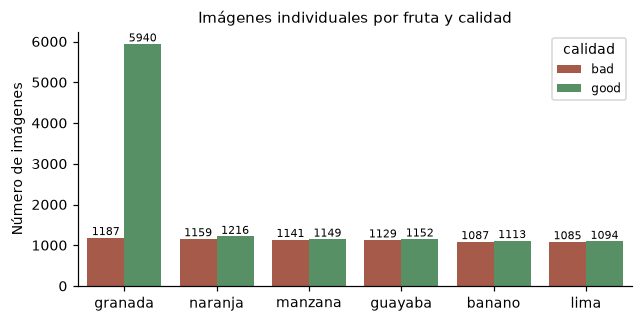

In [5]:
indiv = inv[inv["calidad"].isin(["good", "bad"])]
fig, ax = plt.subplots(figsize=(6.5, 3))
orden = indiv["fruta"].value_counts().index
sns.countplot(data=indiv, x="fruta", hue="calidad", order=orden, palette={"good": "#4c9a5f", "bad": "#b5523b"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Número de imágenes")
ax.set_title("Imágenes individuales por fruta y calidad")
for c in ax.containers:
    ax.bar_label(c, fontsize=7)
guardar_figura(fig, "eda_conteos_fruta_calidad")
plt.show()

In [6]:
tabla = pd.crosstab(indiv["fruta"], indiv["calidad"])
tabla["razon_good_bad"] = (tabla["good"] / tabla["bad"]).round(2)
tabla["pct_del_total"] = (100 * tabla[["good", "bad"]].sum(axis=1) / len(indiv)).round(1)
print("Razón entre la fruta más y menos frecuente:",
      round(tabla[["good", "bad"]].sum(axis=1).max() / tabla[["good", "bad"]].sum(axis=1).min(), 2))
tabla

Razón entre la fruta más y menos frecuente: 3.27


calidad,bad,good,razon_good_bad,pct_del_total
fruta,,,,
banano,1087,1113,1.02,11.9
granada,1187,5940,5.00,38.6
guayaba,1129,1152,1.02,12.4
lima,1085,1094,1.01,11.8
manzana,1141,1149,1.01,12.4
naranja,1159,1216,1.05,12.9


## 3. Resolución y formato

In [7]:
inv["resolucion"] = inv["ancho"].astype(str) + "x" + inv["alto"].astype(str)
print(pd.crosstab(inv["resolucion"], inv["calidad"]))
print("\nTamaño medio del archivo (KB) por calidad:")
print((inv.groupby("calidad")["bytes"].mean() / 1024).round(1))

calidad      bad  good  mixed
resolucion                   
144x256       12     0      0
192x256     2775  1193    568
256x144        9     0      0
256x192      527   864    506
256x256     3465  9043      0
3000x4000      0   381      0
8000x6000      0   183      0

Tamaño medio del archivo (KB) por calidad:
calidad
bad       19.8
good     262.8
mixed     13.0
Name: bytes, dtype: float64


## 4. Ejemplos por fruta y calidad

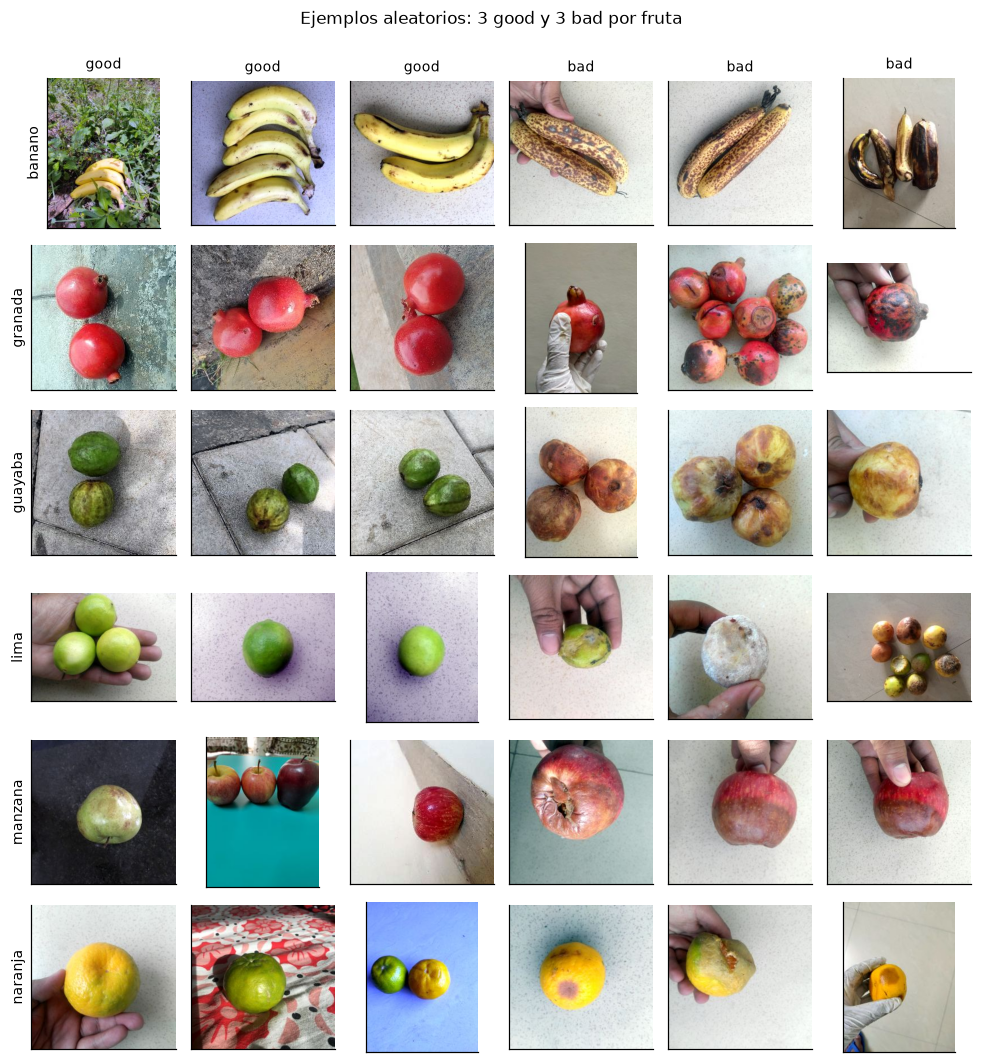

In [8]:
frutas = sorted(indiv["fruta"].unique())
fig, axes = plt.subplots(len(frutas), 6, figsize=(9, 1.6 * len(frutas)))
for i, f in enumerate(frutas):
    for j, cal in enumerate(["good"] * 3 + ["bad"] * 3):
        sub = indiv[(indiv["fruta"] == f) & (indiv["calidad"] == cal)]
        fila = sub.iloc[rng.integers(len(sub))]
        axes[i, j].imshow(leer_rgb(DATA_RAW_KAGGLE / fila["ruta"]))
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if j == 0:
            axes[i, j].set_ylabel(f, fontsize=9)
        if i == 0:
            axes[i, j].set_title(cal, fontsize=9)
fig.suptitle("Ejemplos aleatorios: 3 good y 3 bad por fruta", y=1.0)
fig.tight_layout()
guardar_figura(fig, "eda_ejemplos", raster=True)
plt.show()

## 5. Condiciones de captura: brillo, saturación, nitidez y fondo

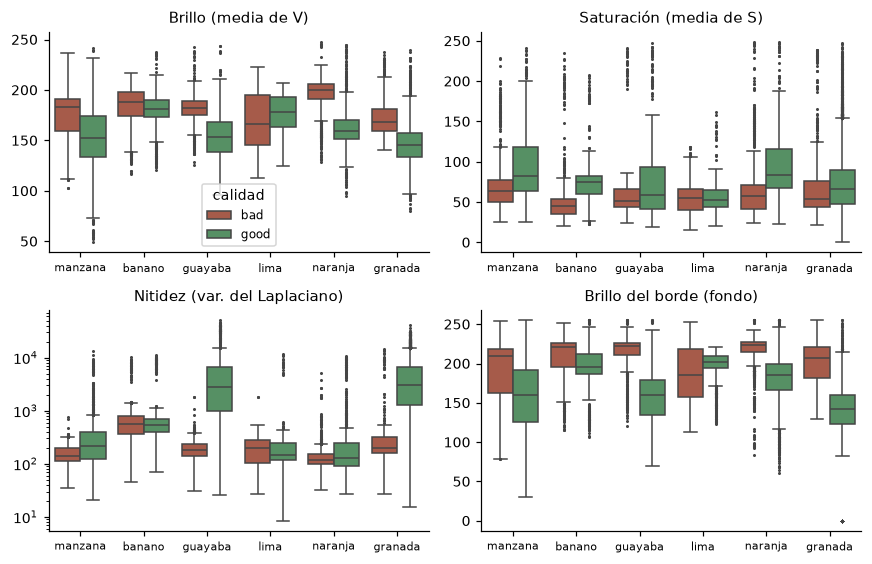

brillo  saturacion  nitidez  fondo_v
fruta   calidad                                      
banano  bad       188.3        44.6    551.5    221.0
        good      181.1        74.7    549.1    196.0
granada bad       168.2        54.0    202.1    207.0
        good      145.5        66.4   3075.5    142.0
guayaba bad       182.0        51.9    185.3    222.0
        good      153.5        58.4   2781.1    160.0
lima    bad       166.6        55.0    201.0    186.0
        good      178.6        53.0    147.8    202.0
manzana bad       182.9        63.3    139.1    210.0
        good      152.6        82.8    212.6    160.0
naranja bad       200.4        57.2    118.9    223.0
        good      159.1        83.5    131.4    185.0

In [9]:
variables = {"brillo": "Brillo (media de V)", "saturacion": "Saturación (media de S)",
             "nitidez": "Nitidez (var. del Laplaciano)", "fondo_v": "Brillo del borde (fondo)"}
fig, axes = plt.subplots(2, 2, figsize=(8, 5.2))
for ax, (col, titulo) in zip(axes.ravel(), variables.items()):
    sns.boxplot(data=indiv, x="fruta", y=col, hue="calidad", ax=ax, fliersize=1,
                palette={"good": "#4c9a5f", "bad": "#b5523b"})
    ax.set_title(titulo); ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=7)
    if col == "nitidez":
        ax.set_yscale("log")
    if ax is not axes[0, 0]:
        ax.get_legend().remove()
fig.tight_layout()
guardar_figura(fig, "eda_condiciones_captura")
plt.show()

resumen = indiv.groupby(["fruta", "calidad"])[list(variables)].median().round(1)
resumen.to_csv(RESULTADOS / "eda_condiciones_captura.csv")
resumen

## 6. ¿El color separa las clases?

Se segmenta la fruta (`src/data/segmentacion.py`) en una muestra de 60 imágenes por fruta y calidad y se mide, **solo sobre los píxeles de la fruta**:
- el histograma de tono (H de HSV),
- la proporción de píxeles oscuros ($V < 80$), que aproxima manchas y podredumbre.

In [10]:
def resumen_color(ruta, umbral_v=80):
    img = cv2.cvtColor(leer_rgb(ruta), cv2.COLOR_RGB2BGR)
    m = mascara_fruta(img) > 0
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h = hsv[..., 0][m]
    v = hsv[..., 2][m]
    hist = np.histogram(h, bins=36, range=(0, 180))[0] / max(1, m.sum())
    return hist, float((v < umbral_v).mean()) if m.any() else np.nan, float(m.mean())

filas = []
for (f, cal), sub in indiv.groupby(["fruta", "calidad"]):
    muestra = sub.sample(min(60, len(sub)), random_state=SEMILLA)
    for r in muestra["ruta"]:
        hist, oscuro, area_rel = resumen_color(DATA_RAW_KAGGLE / r)
        filas.append({"fruta": f, "calidad": cal, "hist": hist, "pct_oscuro": oscuro, "area_rel": area_rel})
color = pd.DataFrame(filas)
color.groupby(["fruta", "calidad"])[["pct_oscuro", "area_rel"]].median().round(3)

pct_oscuro  area_rel
fruta   calidad                      
banano  bad           0.202     0.200
        good          0.141     0.126
granada bad           0.170     0.255
        good          0.037     0.189
guayaba bad           0.128     0.232
        good          0.170     0.113
lima    bad           0.247     0.162
        good          0.200     0.130
manzana bad           0.091     0.258
        good          0.031     0.148
naranja bad           0.084     0.191
        good          0.179     0.195

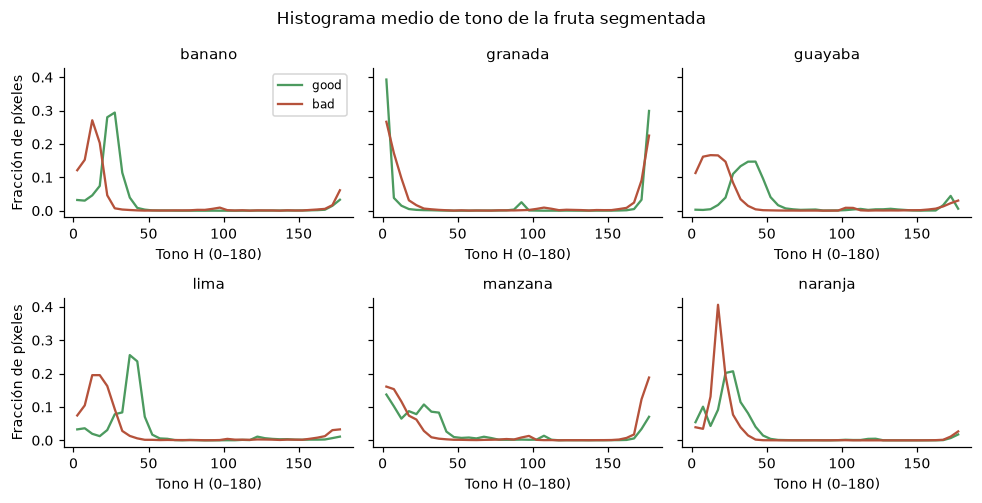

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(9, 4.6), sharey=True)
centros = np.arange(36) * 5 + 2.5
for ax, f in zip(axes.ravel(), frutas):
    for cal, colr in [("good", "#4c9a5f"), ("bad", "#b5523b")]:
        h = np.stack(color[(color["fruta"] == f) & (color["calidad"] == cal)]["hist"]).mean(axis=0)
        ax.plot(centros, h, color=colr, label=cal)
    ax.set_title(f); ax.set_xlabel("Tono H (0–180)")
axes[0, 0].set_ylabel("Fracción de píxeles"); axes[1, 0].set_ylabel("Fracción de píxeles")
axes[0, 0].legend()
fig.suptitle("Histograma medio de tono de la fruta segmentada")
fig.tight_layout()
guardar_figura(fig, "eda_histograma_tono")
plt.show()

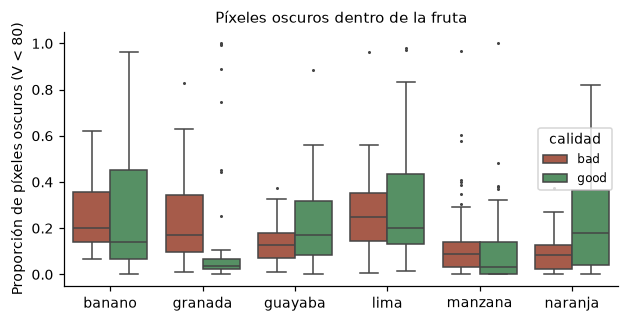

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3))
sns.boxplot(data=color, x="fruta", y="pct_oscuro", hue="calidad", ax=ax, fliersize=1,
            palette={"good": "#4c9a5f", "bad": "#b5523b"})
ax.set_ylabel("Proporción de píxeles oscuros (V < 80)"); ax.set_xlabel("")
ax.set_title("Píxeles oscuros dentro de la fruta")
guardar_figura(fig, "eda_pixeles_oscuros")
plt.show()

### Ejemplos de segmentación

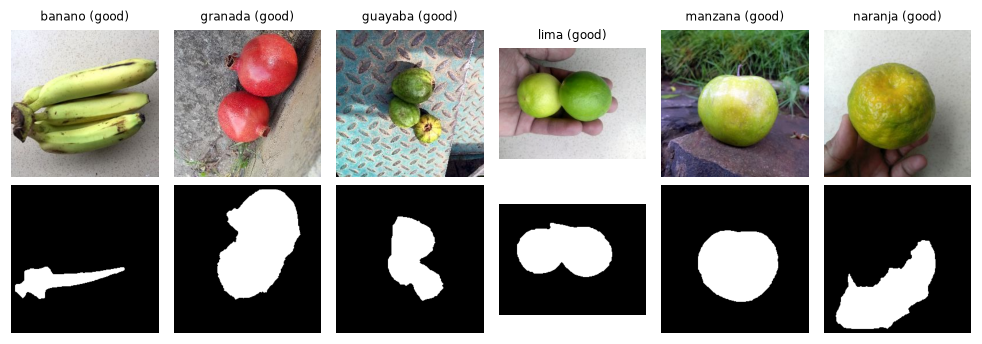

In [13]:
fig, axes = plt.subplots(2, 6, figsize=(9, 3.2))
for j, f in enumerate(frutas):
    fila = indiv[indiv["fruta"] == f].sample(1, random_state=SEMILLA + j).iloc[0]
    rgb = leer_rgb(DATA_RAW_KAGGLE / fila["ruta"])
    m = mascara_fruta(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
    axes[0, j].imshow(rgb); axes[0, j].set_title(f"{f} ({fila['calidad']})", fontsize=8)
    axes[1, j].imshow(m, cmap="gray")
    for a in axes[:, j]:
        a.axis("off")
fig.tight_layout()
guardar_figura(fig, "eda_ejemplos_segmentacion", raster=True)
plt.show()

## 7. Duplicados exactos

In [14]:
dup = inv[inv.duplicated("md5", keep=False)].sort_values("md5")
print("Imágenes con al menos un duplicado exacto:", len(dup))
print("Grupos de duplicados:", dup["md5"].nunique())
dup.groupby("md5").agg(n=("ruta", "size"), calidades=("calidad", lambda s: ",".join(sorted(set(s))))).head(10)

Imágenes con al menos un duplicado exacto: 0
Grupos de duplicados: 0


,n,calidades
md5,,


## 8. Imágenes `mixed_quality`

Imágenes mixed por fruta:
fruta
banano     285
lima       278
guayaba    148
naranja    125
granada    125
manzana    113
Name: count, dtype: int64


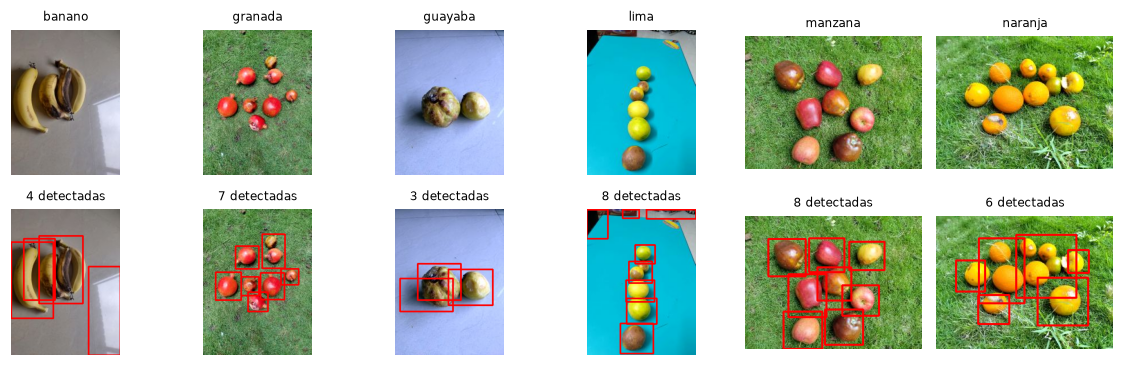

In [15]:
mixed = inv[inv["calidad"] == "mixed"]
print("Imágenes mixed por fruta:")
print(mixed["fruta"].value_counts())

muestra = mixed.groupby("fruta").sample(n=min(1, len(mixed)), random_state=SEMILLA)
fig, axes = plt.subplots(2, len(muestra), figsize=(1.6 * len(muestra) + 1, 3.4))
for j, (_, fila) in enumerate(muestra.iterrows()):
    rgb = leer_rgb(DATA_RAW_KAGGLE / fila["ruta"])
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    frs = separar_frutas(bgr)
    vis = rgb.copy()
    for fr in frs:
        x, y, w, h = fr.caja
        cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
    axes[0, j].imshow(rgb); axes[0, j].set_title(fila["fruta"], fontsize=8)
    axes[1, j].imshow(vis); axes[1, j].set_title(f"{len(frs)} detectadas", fontsize=8)
    for a in axes[:, j]:
        a.axis("off")
fig.tight_layout()
guardar_figura(fig, "eda_mixed_ejemplos", raster=True)
plt.show()

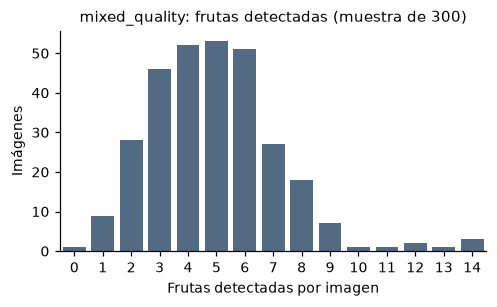

,count,mean,std,min,25%,50%,75%,max
fruta,,,,,,,,
banano,78.0,4.27,2.10,1.0,3.0,4.0,6.00,12.0
granada,34.0,5.56,1.93,1.0,5.0,6.0,6.75,9.0
guayaba,43.0,3.81,1.28,1.0,3.0,4.0,5.00,7.0
lima,76.0,5.18,2.19,0.0,4.0,5.0,6.00,14.0
manzana,37.0,4.92,1.93,2.0,4.0,4.0,6.00,8.0
naranja,32.0,6.75,3.20,1.0,5.0,6.0,8.00,14.0


In [16]:
n_frutas = []
for _, fila in mixed.sample(min(300, len(mixed)), random_state=SEMILLA).iterrows():
    bgr = cv2.cvtColor(leer_rgb(DATA_RAW_KAGGLE / fila["ruta"]), cv2.COLOR_RGB2BGR)
    n_frutas.append({"fruta": fila["fruta"], "n": len(separar_frutas(bgr))})
n_frutas = pd.DataFrame(n_frutas)
fig, ax = plt.subplots(figsize=(5, 2.6))
sns.countplot(data=n_frutas, x="n", color="#4a6b8a", ax=ax)
ax.set_xlabel("Frutas detectadas por imagen"); ax.set_ylabel("Imágenes")
ax.set_title("mixed_quality: frutas detectadas (muestra de 300)")
guardar_figura(fig, "eda_mixed_conteo")
plt.show()
n_frutas.groupby("fruta")["n"].describe().round(2)

## 9. Hallazgos y decisiones

**Estructura.** 19.526 imágenes legibles, sin duplicados exactos: 11.664 *good*, 6.788 *bad* y 1.074 *mixed*, de 6 frutas. La calidad original es **binaria** (good/bad); *mixed* son escenas con varias frutas sin etiqueta individual.

**Desbalance.** Banano, guayaba, lima, manzana y naranja están casi balanceadas (razón good/bad entre 1,01 y 1,05). Granada concentra el 38,6 % de las imágenes individuales y tiene razón 5:1, así que dominaría cualquier modelo entrenado con todas las frutas.

**Sesgo de captura (hallazgo principal).** Las clases no se fotografiaron en las mismas condiciones:
- Resolución: todas las imágenes de 3000×4000 y 8000×6000 son *good*; las *bad* son de 256×256 o 192×256.
- Fondo: en cinco de las seis frutas el borde de las *bad* es más claro (mediana del brillo del borde entre 186 y 223) que el de las *good* (entre 142 y 202); la excepción es lima. Las *bad* se tomaron casi siempre sobre baldosa clara y con la mano; las *good*, sobre pasto, pisos y telas.
- Nitidez: en guayaba y granada la varianza del Laplaciano de las *good* es más de 10 veces la de las *bad*.

Un modelo entrenado con la imagen completa podría aprender el fondo o la resolución en lugar de la calidad (aprendizaje por atajos). Decisiones: redimensionar todo a un tamaño común, segmentar la fruta y enmascarar el fondo antes de extraer características, aumentar datos con cambios de brillo y fondo, y medir la generalización con fotos propias tomadas en condiciones uniformes.

**El color sí separa la calidad, pero depende de la fruta.** El histograma de tono de la fruta segmentada se desplaza hacia el café/naranja (H < 20) en banano, guayaba y lima malos. La proporción de píxeles oscuros es mayor en las *bad* de granada, manzana y banano, pero no en naranja ni guayaba, donde la fruta buena es verde y más oscura. Por eso las características se calcularán sobre la fruta segmentada y el modelo debe conocer la fruta (modelo por fruta o fruta como variable).

**Supuesto de una fruta por foto.** Muchas imágenes individuales tienen 2 a 8 frutas, manos o fondos con textura. La segmentación por umbral sobre la distancia al fondo falla en esos casos; se agregó un refinamiento con GrabCut (notebook 02).

**mixed_quality.** Escenas de 256×192 con 3,8 a 6,8 frutas detectadas en promedio según la fruta (muestra de 300), sobre pasto o láminas de color. Las frutas se separan con watershed y los recortes requieren etiqueta manual de calidad.

**Decisiones que se proponen** (ver `docs/crisp-dm/02_comprension_datos.md`):
1. Trabajar con **manzana, banano y naranja** (decisión del equipo): están balanceadas, se consiguen en Cali y su sesgo de nitidez entre clases es pequeño (1,0× a 1,5×). Guayaba se descarta porque la nitidez de sus *good* es unas 15 veces la de sus *bad*, un atajo que el modelo podría aprender. Granada se descarta por el desbalance y porque es difícil de conseguir; lima queda como alternativa.
2. Tres clases de calidad: **buena** (good), **mala** (bad con defecto extenso) y **regular** (defecto leve o sobremaduración), construida con reetiquetado manual asistido de las *bad* y con los recortes de *mixed*.